# Method 1 · Pre-trained CNNs + Transfer Learning

ImageNet-pretrained CNN backbones are transferred to brain MRI. Two routes are implemented: fine-tuning a single backbone (EfficientNet-B0 or ResNet-50, chosen on validation macro-F1), and a feature-fusion ensemble in which frozen GoogleNet, VGG16, ResNet-50 and AlexNet branches are concatenated and weighed by a trained meta-learner. Whichever checkpoint is on disk is the one served, and it was evaluated once on the held-out test set.

**Modality:** MRI
**Classifier:** Feature-fusion ensemble of frozen GoogleNet + VGG16 + ResNet-50 + AlexNet branches with a trained meta-learner, or a single fine-tuned backbone — whichever checkpoint is present
**Segmentation:** Not part of this method (whole-image classification)
**Optimisation:** Backbone and route selection by validation macro-F1; branch weighting learned by the meta-learner

Nothing here trains anything. Every number is read from a recorded evaluation,
every image is produced by the checkpoint on disk, and the training commands are
printed rather than run.

## 1 · Setup

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "backend").is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np

from backend import config
from backend.methods.registry import get_method, load_engine, runtime_status
from backend.methods.common.metrics_store import read_metrics, metrics_for

plt.rcParams["figure.dpi"] = 110
print("project root :", ROOT)
print("device       :", config.DEVICE)
print("dataset      :", config.BRI_DATASET_PATH)

project root : /Users/syedasif/tumb
device       : mps
dataset      : /Users/syedasif/tumb/data/bri/archive


In [2]:
import json

def show(images, titles, width=4.2):
    """Draw images side by side with their titles."""
    images = [i for i in images if i is not None]
    fig, axes = plt.subplots(1, len(images), figsize=(width * len(images), width))
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        ax.imshow(image if image.ndim == 2 else image[..., ::-1], cmap="gray" if image.ndim == 2 else None)
        ax.set_title(title, fontsize=10)
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def read(path):
    import cv2
    return None if path is None else cv2.imread(str(path), cv2.IMREAD_UNCHANGED)


def table(rows, headers):
    """A plain-text table, so the notebook reads the same with or without pandas."""
    widths = [max(len(str(r[i])) for r in [headers, *rows]) for i in range(len(headers))]
    line = "  ".join(h.ljust(w) for h, w in zip(headers, widths))
    print(line)
    print("  ".join("-" * w for w in widths))
    for row in rows:
        print("  ".join(str(c).ljust(w) for c, w in zip(row, widths)))

In [3]:
METHOD = "method3"
spec = get_method(METHOD)
status = runtime_status(spec)

print(f"Method {spec.display_number} — {spec.display_name}\n")
for stage in spec.pipeline:
    print(f"  {stage.id:<16}{stage.label:<28}{stage.description}")
print()
table([[role, w["architecture"], "yes" if w["present"] else "NO", w["model_version"] or "—"]
       for role, w in status["weights"].items()],
      ["role", "architecture", "checkpoint", "version"])

Method 1 — Deep Learning Pre-trained Models + Transfer Learning-Based Brain Tumor Classification

  input           Input MRI                   Single MRI slice (PNG/JPG/TIFF).
  preprocess      Preprocessing               Grayscale, resize to 224×224, replicate to 3 channels, ImageNet normalisation.
  pretrained      Pre-trained backbones       GoogleNet, VGG16, ResNet-50 and AlexNet with ImageNet weights (EfficientNet-B0 on the single-backbone route).
  transfer        Transfer learning           Fusion route: backbones frozen, a 64-d head per branch. Single-backbone route: head warm-up, then full fine-tuning at a lower learning rate.
  fusion          Feature fusion              The four branch vectors are concatenated and weighed by a meta-learner (256 → 128 → 64 → classes).
  select          Model selection             Backbone and route chosen by validation macro-F1 (test set untouched).
  predict         Prediction                  Glioma / Meningioma / No Tumor / Pituitary.
  g

## 2 · The data

The images below come from the dataset's own **Testing** folder — the held-out
split the metrics further down were measured on. They are examples, not
predictions.

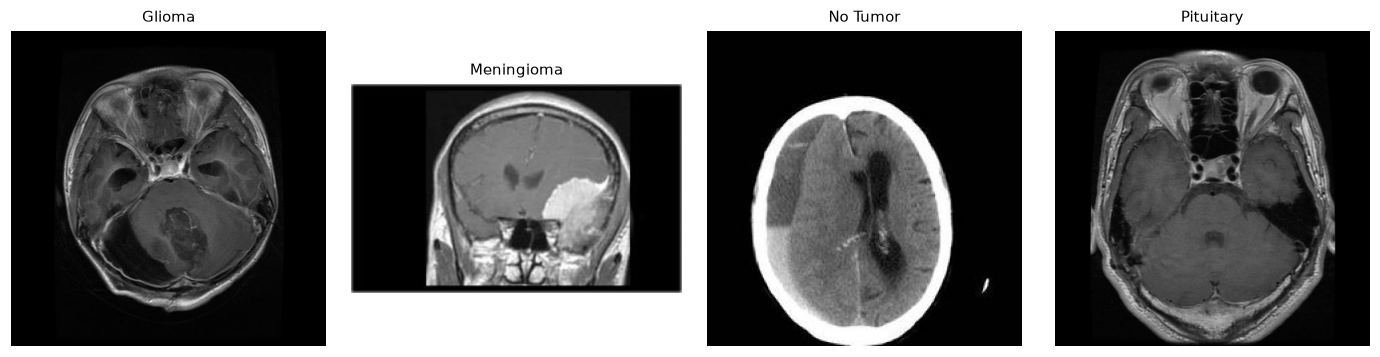

class       example file    
----------  ----------------
Glioma      Te-glTr_0000.jpg
Meningioma  Te-meTr_0000.jpg
No Tumor    Te-noTr_0000.jpg
Pituitary   Te-piTr_0000.jpg


In [4]:
root = config.BRI_DATASET_PATH / "Testing"
samples = {}
for class_key in spec.class_names:
    folder = root / ({"normal": "notumor"}.get(class_key, class_key))
    files = sorted(folder.glob("*.jpg"))[:1] if folder.is_dir() else []
    if files:
        samples[spec.class_labels[class_key]] = files[0]

show([read(p) for p in samples.values()], list(samples), width=3.2)
table([[label, path.name] for label, path in samples.items()], ["class", "example file"])

## 3 · Preprocessing

The geometry is read from the checkpoint, not chosen here: a model is served the
same transform it was trained with.

In [5]:
engine = load_engine(METHOD)
engine.load()
transform = status["weights"].get("classification", {}).get("transform_id")
print("transform recorded in the checkpoint:", transform or "—")

import importlib
transforms = importlib.import_module(spec.transforms_module)
spec_obj = transforms.get_spec(transform) if hasattr(transforms, "get_spec") else transforms.DEFAULT_SPEC
for k, v in spec_obj.to_dict().items():
    print(f"  {k:<16}{v}")

transform recorded in the checkpoint: m3-gray224-rgb-imagenet
  id              m3-gray224-rgb-imagenet
  image_size      224
  channels        3
  normalisation   ImageNet mean/std
  description     Grayscale, resize to 224×224 (area interpolation when shrinking), replicate to 3 channels, ImageNet normalisation. Training adds GPU augmentation only.


## 4 · The model as loaded

Built from the checkpoint's own record of its hyper-parameters, then the stored
weights are loaded into it. A checkpoint that belonged to another method, or to
other classes, is refused rather than coerced.

In [6]:
model = getattr(engine, "model", None) or getattr(engine, "cls_model", None)
print(type(model).__name__)
print(f"{sum(p.numel() for p in model.parameters()):,} parameters")
print()
for key, value in (engine.meta if hasattr(engine, "meta") else engine.cls_meta).items():
    if key != "extra":
        print(f"  {key:<18}{value}")

FusionEnsemble
47,548,964 parameters

  format            2
  method_id         method3
  architecture      FusionEnsembleCNN
  role              classification
  class_names       ['glioma', 'meningioma', 'notumor', 'pituitary']
  image_size        224
  transform_id      m3-gray224-rgb-imagenet
  model_version     20261016-204819
  created_at        2026-10-16T20:48:19+00:00


## 5 · One prediction, with everything it produced

The class, the probabilities, and every image this method writes: the
preprocessed input it actually read, the segmentation mask, the Grad-CAM
heatmap, and — for the fusion method — the fused image.

In [7]:
image_path = list(samples.values())[0]
result = engine.predict(image_path.read_bytes())

print(f"input      : {image_path}")
print(f"prediction : {result.prediction}   {result.confidence}%")
print(f"model      : {result.model_version}   ({result.inference_time_s}s)\n")
for name, value in sorted(result.probabilities.items(), key=lambda kv: -kv[1]):
    print(f"  {name:<14}{'█' * int(value / 4):<25}{value:6.2f}%")

input      : /Users/syedasif/tumb/data/bri/archive/Testing/glioma/Te-glTr_0000.jpg
prediction : Glioma   99.56%
model      : 20261016-204819   (2.2262s)

  Glioma        ████████████████████████  99.56%
  Pituitary                                0.17%
  No Tumor                                 0.15%
  Meningioma                               0.12%


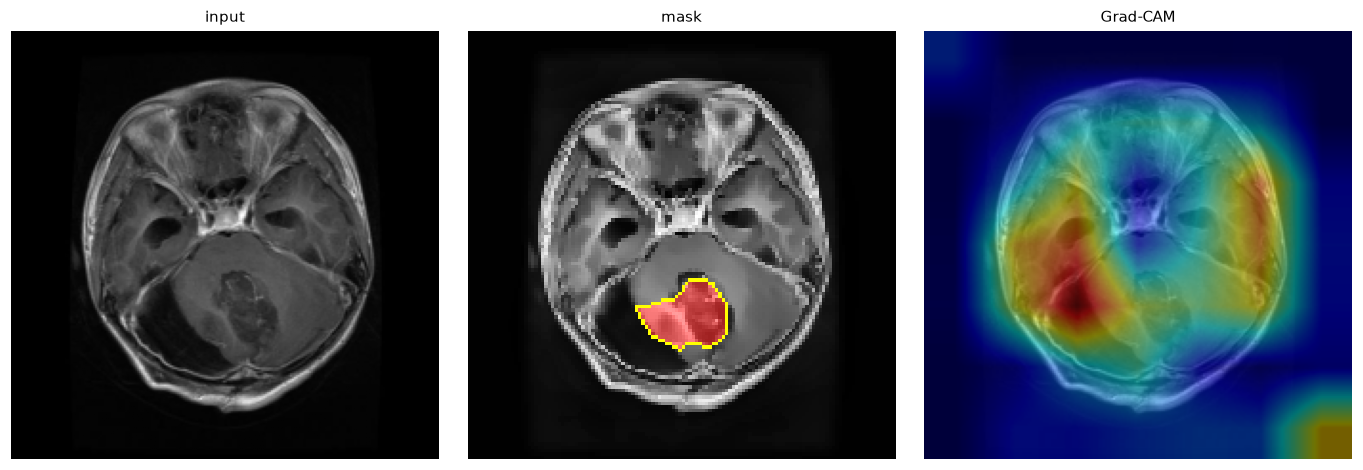

mask: Shown from the U-Net + ConvLSTM method; not part of this method


In [8]:
panels = [("input", result.original_path), ("mask", result.mask_path),
          ("Grad-CAM", result.overlay_path), ("fused", getattr(result, "fused_path", None))]
panels = [(label, path) for label, path in panels if path]
show([read(p) for _, p in panels], [label for label, _ in panels])

note = result.details.get("segmentation_note")
if note:
    print("mask:", note)
if result.details.get("gradcam_note"):
    print("Grad-CAM:", result.details["gradcam_note"])

## 6 · The recorded held-out evaluation

These numbers are not computed here. They were measured once, by the training
run, on the test split — and are read back from the metrics file so this
notebook cannot quietly disagree with the API.

In [9]:
metrics = metrics_for(METHOD)
table([[k, f"{metrics[k]:.4f}" if metrics[k] is not None else "—"]
       for k in ("accuracy", "precision", "recall", "specificity", "f1", "auc", "dice", "iou")],
      ["metric", "held-out test"])
print()
print(metrics["split"])

metric       held-out test
-----------  -------------
accuracy     0.9512       
precision    0.9503       
recall       0.9496       
specificity  0.9839       
f1           0.9495       
auc          0.9947       
dice         —            
iou          —            

dataset Training/Testing split; validation carved from Training only; image-level split; no patient identifiers


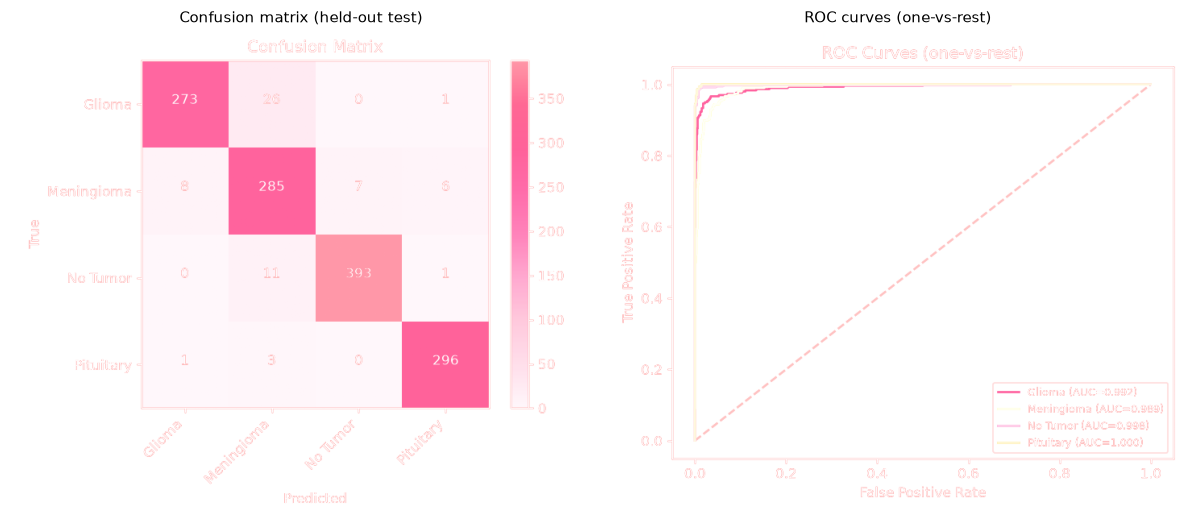

In [10]:
show([read(config.LOGS_DIR / "method3_cls_confusion_matrix.png"),
      read(config.LOGS_DIR / "method3_cls_roc.png")],
     ["Confusion matrix (held-out test)", "ROC curves (one-vs-rest)"], width=5.5)

## 7 · What the four backbones each contribute

The served checkpoint is the fusion ensemble: GoogleNet, VGG16, ResNet-50 and
AlexNet are frozen, each reduced to a 64-d branch vector, and a meta-learner
weighs the concatenation. Only the branch heads and the meta-learner were
trained, which is also why no augmentation was used — an augmented copy would
need its own pass through all four backbones.

In [11]:
meta = json.loads((config.WEIGHTS_DIR / "method3/model_metadata.json").read_text())
print("architecture :", meta["architecture"])
print("frozen       :", ", ".join(meta["frozen_backbones"]))
print("trainable    :", f"{meta['trainable_parameters']:,} parameters")
print("augmentation :", meta["augmentation"])
print("best epoch   :", meta["best_epoch"], "of", meta["epochs_run"])
print()
table([[k, f"{meta['validation_metrics'][k]:.4f}", f"{meta['test_metrics'][k]:.4f}"]
       for k in ("accuracy", "precision", "recall", "f1", "auc")],
      ["metric", "validation", "TEST"])

architecture : FusionEnsembleCNN: googlenet + vgg16 + resnet50 + alexnet -> concat -> meta-learner
frozen       : googlenet, vgg16, resnet50, alexnet
trainable    : 1,256,644 parameters
augmentation : none (frozen-backbone features are cached)
best epoch   : 31 of 43

metric     validation  TEST  
---------  ----------  ------
accuracy   0.9654      0.9512
precision  0.9656      0.9503
recall     0.9656      0.9496
f1         0.9654      0.9495
auc        0.9962      0.9947


## 8 · Caveats

Every warning the method records travels with its numbers. They are part of the
result, not a footnote to it.

In [12]:
seen = set()
for section, values in read_metrics(METHOD).items():
    if not isinstance(values, dict):
        continue
    for warning in values.get("warnings", []) or []:
        if warning not in seen:
            seen.add(warning)
            print(f"[{section}] {warning}\n")

[classification] The Kaggle brain-MRI classification dataset carries no patient identifiers, so samples can only be grouped by image identity (training groups byte-identical copies together). Scores from this dataset may still be optimistic if the same patient appears under unrelated filenames.

[classification] Using the dataset's own Training/Testing split. It is an IMAGE-level split: this dataset ships no patient identifiers, so slices from one patient may appear on both sides and the test score can be optimistic.

[classification] Dropped 134 Training images that are byte-identical to a Testing image, so the test score is not inflated by memorised copies. The Testing set itself was not modified.

[classification] The fusion ensemble trains on cached frozen-backbone features, so no augmentation is applied: an augmented copy would need its own pass through all four backbones.



## 9 · Reproducing this

```bash
python -m backend.methods.method3.training.train_fusion
python -m backend.methods.method3.training.train_classifier
```

Or run every method on one image from a terminal:

```bash
python -m backend.cli.run_methods data/bri/archive/Testing/glioma/Te-gl_0012.jpg
```